<div dir="rtl" style="text-align: right;">

# دفترچه تمرین عملی (<span dir="ltr">Task Notebook</span>): از ترنسفورمرهای بینایی (<span dir="ltr">ViT</span>) تا پیاده‌سازی <span dir="ltr">CLIP</span> از صفر

به دفترچه تمرین‌های عملی خوش آمدید! در این تمرین، هدف این است که درک عمیقی از مبانی **ترنسفورمرهای بینایی (<span dir="ltr">ViT</span>)** و نحوه کارکرد مدل انقلابی **<span dir="ltr">CLIP</span>** به دست آورید.

<div style="border-right: 4px solid #ed8936; padding-right: 14px; margin: 16px 0;">

</div>

## ۱. راه‌اندازی و بارگذاری داده‌های آموزشی (<span dir="ltr">Setup & Dataset</span>)

سلول‌های زیر محیط و داده‌های نمونه <span dir="ltr">Food-101</span> را آماده می‌کنند (بدون نیاز به تغییر).

</div>

In [2]:
!pip install -q transformers datasets accelerate

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"


In [3]:
from datasets import load_dataset

# مجموعه داده Food-101: شامل ۱۰۱ هزار تصویر واقعی غذا در ۱۰۱ کلاس
# Food-101: 101k real food photographs in 101 classes
food101 = load_dataset("ethz/food101")
class_names = [name.replace("_", " ") for name in food101["train"].features["label"].names]
print(f"Number of classes: {len(class_names)}")
print("Sample classes:", class_names[:10])


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00008.parquet:   0%|          | 0.00/490M [00:00<?, ?B/s]

data/train-00001-of-00008.parquet:   0%|          | 0.00/464M [00:00<?, ?B/s]

data/train-00002-of-00008.parquet:   0%|          | 0.00/472M [00:00<?, ?B/s]

data/train-00003-of-00008.parquet:   0%|          | 0.00/464M [00:00<?, ?B/s]

...

data/validation-00001-of-00003.parquet:   0%|          | 0.00/413M [00:00<?, ?B/s]

data/validation-00002-of-00003.parquet:   0%|          | 0.00/426M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/75750 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25250 [00:00<?, ? examples/s]

Number of classes: 101
Sample classes: ['apple pie', 'baby back ribs', 'baklava', 'beef carpaccio', 'beef tartare', 'beet salad', 'beignets', 'bibimbap', 'bread pudding', 'breakfast burrito']


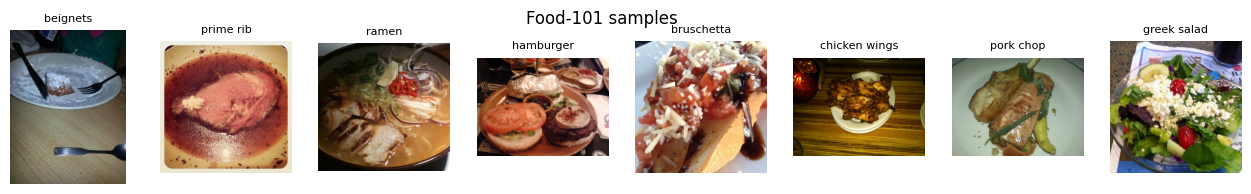

In [4]:
# نمایش چند نمونه تصویر از کلاس‌های مختلف
# Show a few examples across different classes
sample_indices = [i * 750 for i in range(8)]
fig, axes = plt.subplots(1, 8, figsize=(16, 2))
for ax, idx in zip(axes, sample_indices):
    ax.imshow(food101["train"][idx]["image"])
    ax.set_title(class_names[food101["train"][idx]["label"]], fontsize=8)
    ax.axis("off")
plt.suptitle("Food-101 samples")
plt.show()


<div dir="rtl" style="text-align: right;">

---

# ۲. بررسی کوتاه ترنسفورمر بینایی

چرا آموزش را با یک بررسی سریع از <span dir="ltr">ViT</span> شروع می‌کنیم؟ 
زیرا انکودر بینایی (<span dir="ltr">Visual Backbone</span>) در مدل چندوجهی <span dir="ltr">CLIP</span> دقیقاً یک ترنسفورمر بینایی است! بنابراین برای درک چگونگی فهم تصویر در <span dir="ltr">CLIP</span>، ابتدا باید ببینیم ترنسفورمرها با تصاویر دو‌بعدی چگونه رفتار می‌کنند.

شبکه‌های کانوولوشنی سنتی (<span dir="ltr">CNNs</span>) با فیلترهای موضعی کوچک روی پیکسل‌ها کار می‌کردند. اما ترنسفورمر بینایی (<span dir="ltr">Dosovitskiy et al., 2020</span>) تصویر را درست مانند **یک جمله متشکل از تکه‌ها (<span dir="ltr">Sentence of Patches</span>)** می‌بیند:

1. **قطعه‌بندی تصویر (<span dir="ltr">Patchification</span>):** یک تصویر ورودی با ابعاد <span dir="ltr">224×224</span> به تکه‌های پیکسلی با ابعاد <span dir="ltr">16×16</span> برش می‌خورد. بنابراین در کل داریم:
<div dir="ltr" style="text-align: center; margin: 10px 0;">
$$\frac{224}{16} \times \frac{224}{16} = 14 \times 14 = 196 \text{ تکه (Patch)}$$
</div>
این ۱۹۶ تکه، درست مشابه ۱۹۶ کلمه در یک جمله متنی پردازش می‌شوند!
2. **تصویرسازی خطی (<span dir="ltr">Linear Projection</span>):** هر تکه ۳ کاناله پس از مسطح شدن (<span dir="ltr">16×16×3 = 768 بعد</span>)، توسط یک لایه خطی به بعد تعبیه مدل (<span dir="ltr">Embedding Dimension</span>) نگاشت می‌شود.
3. **توکن طبقه‌بندی <code dir="ltr">[CLS]</code>:** مشابه مدل <span dir="ltr">BERT</span> در <span dir="ltr">NLP</span>، یک بردار ویژه قابل یادگیری در ابتدای دنباله توکن‌ها قرار می‌گیرد (مجموعاً ۱۹۷ توکن). وظیفه این توکن این است که با بهره‌گیری از مکانیزم خودتوجه (<span dir="ltr">Self-Attention</span>)، اطلاعات کلیدی تمام ۱۹۶ تکه تصویر را در خود تجمیع کند تا بازنمایی نهایی کل تصویر باشد.
4. **بردارهای موقعیت مکانی (<span dir="ltr">Positional Embeddings</span>):** ترنسفورمر ذاتاً ترتیبی را نمی‌شناسد (<span dir="ltr">Permutation Invariant</span> است)؛ به همین خاطر به هر توکن یک بردار موقعیت اضافه می‌شود تا موقعیت مکانی هر تکه در تصویر برای مدل قابل درک باشد.

در این بخش، ما این لایه‌ها را از پایه نمی‌نویسیم؛ بلکه مدل از پیش‌آموزش‌دیده <code dir="ltr">google/vit-base-patch16-224</code> را بارگذاری کرده و عملکرد درونی آن را کالبدشکافی می‌کنیم.

</div>

In [5]:
from transformers import ViTImageProcessor, ViTForImageClassification

vit_processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224")
vit_model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224", output_attentions=True  # فعال‌سازی استخراج وزن‌های توجه (attention weights)
).eval().to(device)

imagenet_labels = list(vit_model.config.id2label.values())
print(f"ViT has {sum(p.numel() for p in vit_model.parameters())/1e6:.0f}M parameters")


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViT has 87M parameters


<div dir="rtl" style="text-align: right;">

## ۲-الف. تکه‌تکه کردن تصویر (<span dir="ltr">Patchification</span>) — ورودی واقعی <span dir="ltr">ViT</span>

برای ایجاد یک تصویر شهودی و ملموس در ذهن، بیایید یک تصویر نمونه از دیتاست <span dir="ltr">Food-101</span> را انتخاب کرده، ابعاد آن را به <span dir="ltr">224×224</span> تغییر دهیم و عملاً آن را به ۱۹۶ تکه مجزای <span dir="ltr">16×16</span> پیکسلی برش بزنیم.
این شبکه ۱۹۶ تکه‌ای دقیقاً همان چیزی است که شبکه ترنسفورمر به صورت دنباله‌ای از توکن‌ها دریافت می‌کند!
سپس مدل <span dir="ltr">ViT</span> را روی این تصویر اجرا کرده و ۵ پیش‌بینی برتر آن را بر اساس برچسب‌های <span dir="ltr">ImageNet</span> مشاهده می‌کنیم.

</div>

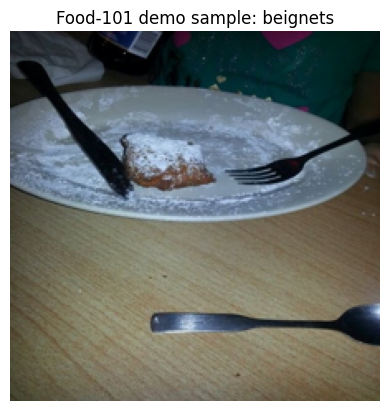

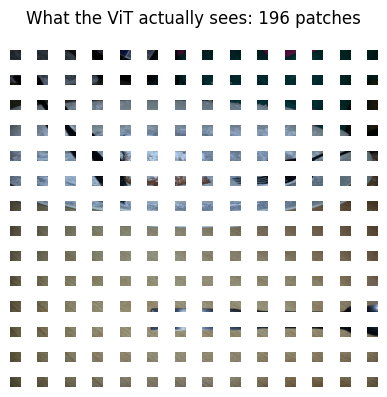

Top-5 ImageNet predictions: ['plate', 'chocolate sauce, chocolate syrup', 'ice cream, icecream', 'eggnog', 'tray']


In [6]:
def show_patchification(image, patch_size=16):
    w, h = image.size
    fig, axes = plt.subplots(h // patch_size, w // patch_size, figsize=(4, 4))
    for i in range(h // patch_size):
        for j in range(w // patch_size):
            patch = image.crop((j*patch_size, i*patch_size, (j+1)*patch_size, (i+1)*patch_size))
            axes[i, j].imshow(patch)
            axes[i, j].axis("off")
    plt.suptitle("What the ViT actually sees: 196 patches", y=0.98)
    plt.tight_layout()
    plt.show()

# تغییر اندازه یک تصویر از Food-101 به 224x224 برای ورودی ViT
demo_img = food101["train"][0]["image"].convert("RGB").resize((224, 224))
demo_label = class_names[food101["train"][0]["label"]]
plt.imshow(demo_img)
plt.title(f"Food-101 demo sample: {demo_label}")
plt.axis("off")
plt.show()
show_patchification(demo_img)

# اجرای مدل ViT روی تصویر
inputs = vit_processor(images=demo_img, return_tensors="pt").to(device)
with torch.no_grad():
    vit_out = vit_model(**inputs)
top5 = vit_out.logits[0].topk(5).indices.tolist()
print("Top-5 ImageNet predictions:", [imagenet_labels[i] for i in top5])


<div dir="rtl" style="text-align: right;">

## ۲-ب. 👀 بصری‌سازی توجه توکن <code dir="ltr">[CLS]</code> — مدل به کدام بخش‌ها نگاه می‌کند؟

در هر لایه از ترنسفورمر، مکانیسم توجه خودکار (<span dir="ltr">Self-Attention</span>) یک ماتریس وزن توجه به ابعاد **۱۹۷×۱۹۷** محاسبه می‌کند (۱۹۷ = ۱ توکن <code dir="ltr">[CLS]</code> + ۱۹۶ تکه تصویر).

**چرا سطر صفرم این ماتریس برای ما بی‌نهایت آموزنده است؟**  
سطر <code dir="ltr">0</code> نشان‌دهنده **میزان توجه توکن <code dir="ltr">[CLS]</code> به تک‌تک تکه‌های تصویر** است. از آنجا که خروجی همین توکن <code dir="ltr">[CLS]</code> تصمیم نهایی طبقه‌بندی را تعیین می‌کند، با استخراج سطر اول دقیقاً متوجه می‌شویم مدل برای طبقه‌بندی تصویر، به کدام بخش‌های آن توجه کرده است.

<div style="border-right: 4px solid #3182ce; padding-right: 14px; margin: 15px 0;">

**مراحل ریاضی استخراج نقشه حرارتی (<span dir="ltr">Attention Heatmap</span>):**
1. استخراج سطر صفرم و نادیده گرفتن ستون اول (توجه <code dir="ltr">[CLS]</code> به خودش) &larr; بردار با بعد ۱۹۶.
2. میانگین‌گیری روی تمام سرهای توجه (<span dir="ltr">Attention Heads</span>) برای دستیابی به نقشه جامع توجه لایه.
3. تغییر شکل (<span dir="ltr">Reshape</span>) بردار ۱۹۶ تایی به شبکه دوبعدی <span dir="ltr">14×14</span>.
4. بزرگ‌نمایی ملایم (<span dir="ltr">Resize</span>) به ابعاد تصویر اصلی (<span dir="ltr">224×224</span>) و نمایش آن به عنوان لایه شفاف حرارتی (<span dir="ltr">Overlay</span>) روی تصویر اصلی.

</div>

</div>

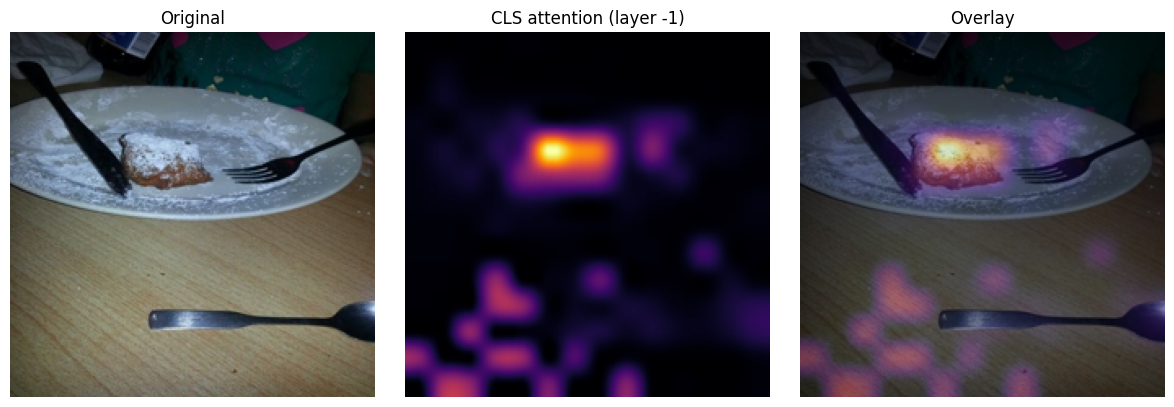

In [ ]:
def show_cls_attention(image, model, processor, layer=-1):
    """نمایش میزان توجه توکن CLS بر روی تصویر اصلی در یک لایه خاص"""
    inputs = processor(images=image, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model(**inputs, output_attentions=True)

    # -------------------------------------------------------------------------
    # TODO 1: استخراج و پردازش وزن‌های توجه توکن [CLS] به تکه‌های تصویر
    # راهنمایی:
    # use out.attentions
    # cls token is the first token in all 1+14*14 = 197 tokens
    # you can take mean over all heads
    # final heat must be a (14, 14) numpy array
    # -------------------------------------------------------------------------
    raise NotImplementedError("TODO 1 را تکمیل کنید: استخراج و پردازش نقشه توجه توکن [CLS]")

    # تغییر ابعاد نقشه حرارتی به ابعاد تصویر اصلی (کدهای رسم بدون نیاز به تغییر)
    heat_img = Image.fromarray((heat / heat.max() * 255).astype(np.uint8)).resize(image.size)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(image); axes[0].set_title("Original")
    axes[1].imshow(heat_img, cmap="inferno"); axes[1].set_title(f"CLS attention (layer {layer})")
    axes[2].imshow(image); axes[2].imshow(heat_img, cmap="inferno", alpha=0.5)
    axes[2].set_title("Overlay")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

show_cls_attention(demo_img, vit_model, vit_processor, layer=-1)  # لایه آخر

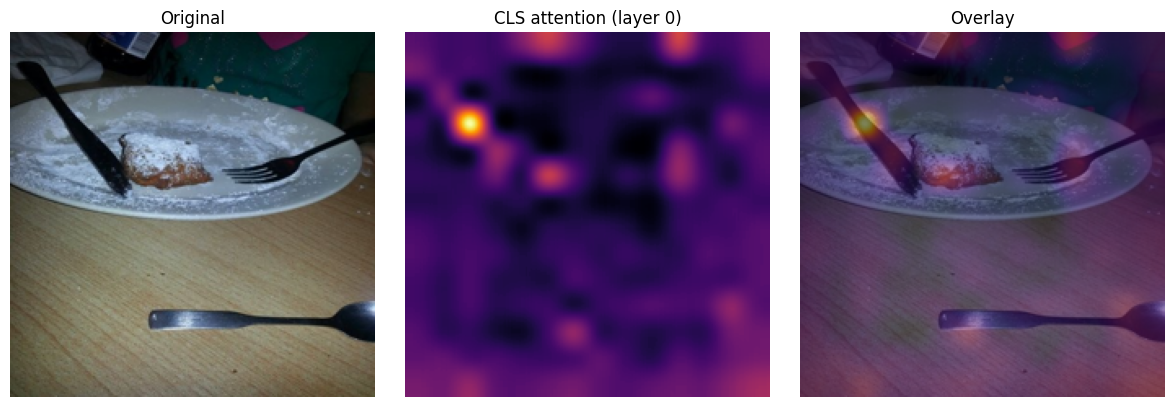

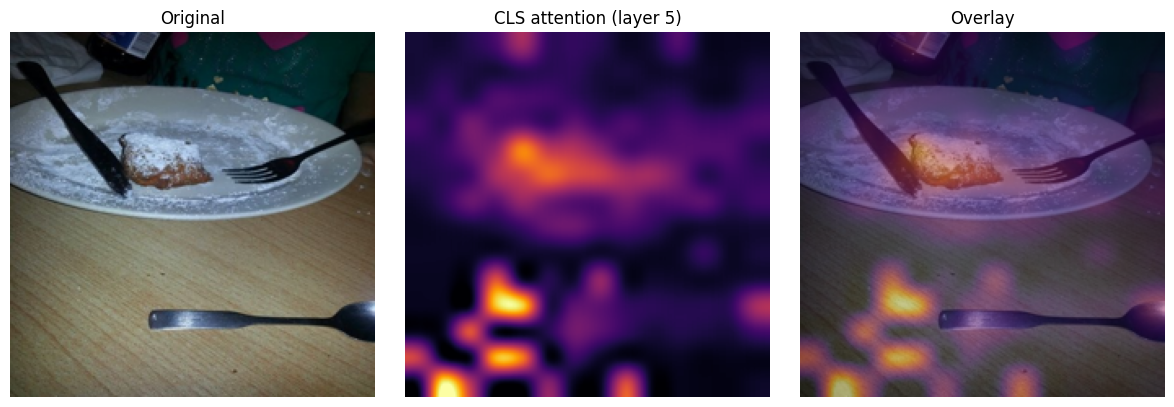

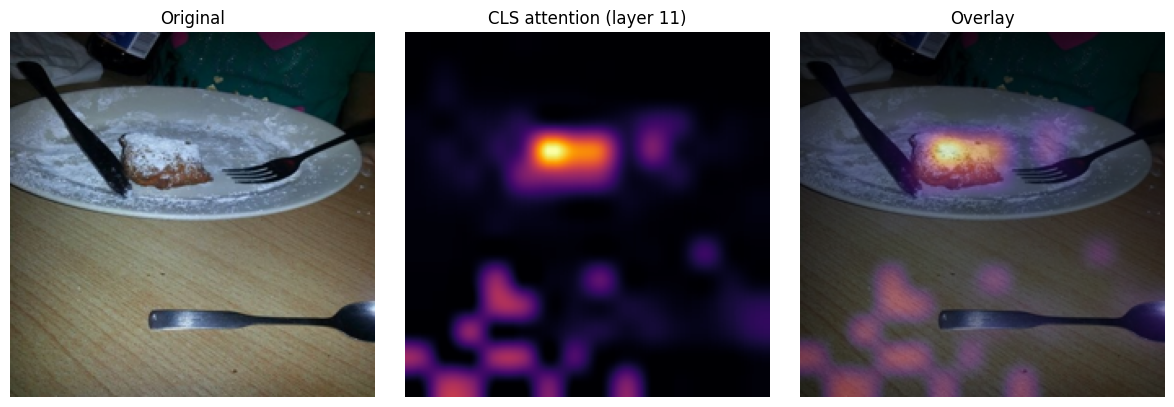

In [8]:
# آزمایش: مقایسه لایه‌های اولیه، میانی و انتهایی
for layer in [0, 5, 11]:
    show_cls_attention(demo_img, vit_model, vit_processor, layer=layer)
# سوال تحلیلی: با افزایش عمق شبکه، نحوه توجه چه تغییری می‌کند و علت آن چیست؟


<div dir="rtl" style="text-align: right;">

<div style="border-right: 4px solid #38a169; padding-right: 14px; margin: 16px 0;">

### 💡 نکته شهودی آموزشی: سیر تحول توجه در لایه‌های <span dir="ltr">ViT</span>
هنگامی که سلول فوق را برای لایه‌های ابتدایی (<code dir="ltr">layer 0</code>)، میانی (<code dir="ltr">layer 5</code>) و انتهایی (<code dir="ltr">layer 11</code>) مقایسه می‌کنید، به این نکات تحلیلی دقت فرمایید:
* **لایه‌های ابتدایی (لایه ۰):** توجه مدل بسیار موضعی (<span dir="ltr">Local</span>) است؛ مدل بیشتر به الگوهای بافت، لبه‌ها، خطوط و تکه‌های مجاور نگاه می‌کند (رفتاری بسیار شبیه فیلترهای اولیه در <span dir="ltr">CNN</span>).
* **لایه‌های میانی (لایه ۵):** مدل شروع به ترکیب اطلاعات تکه‌ها برای تشخیص بخش‌ها و اجزای معنادار شیء (مانند مخلفات، نان، شکل ظرف و ...) می‌کند.
* **لایه‌های عمیق نهایی (لایه ۱۱):** توجه کاملاً معنایی و مفهومی (<span dir="ltr">Semantic</span>) می‌شود؛ توکن <code dir="ltr">[CLS]</code> به صورت هدفمند روی شیء اصلی متمرکز شده و پس‌زمینه کم‌اهمیت را فیلتر می‌کند تا خروجی دقیق دسته‌بندی شکل گیرد.

**🔗 پل انتقال به بخش اصلی درس (CLIP):** اکنون یاد گرفتیم چگونه یک تصویر توسط ترنسفورمر به یک بردار متراکم معنایی تبدیل می‌شود. اکنون سوال اساسی این است: چگونه می‌توانیم این بردار تصویری را با بردار یک متن یا جمله توصیفی هم‌تراز کنیم تا مدل مفهوم عکس را با کلمات بفهمد؟ وارد مبحث اصلی کارگاه یعنی مدل چندوجهی CLIP می‌شویم!

</div>

</div>

<div dir="rtl" style="text-align: right;">

---

# ۳. درک شاخه متنی در <span dir="ltr">CLIP</span>: توکنایزیشن (<span dir="ltr">Tokenization</span>)

برای تسلط بر مدل چندوجهی <span dir="ltr">CLIP</span>، باید هر دو شاخه تصویر و متن را به خوبی بشناسیم. انکودر متن در مدل <span dir="ltr">CLIP</span> یک ترنسفورمر متنی استاندارد است. این مدل نمی‌تواند رشته‌های متنی را به صورت مستقیم پردازش کند؛ بلکه کلمات ابتدا باید به شناسه‌های عددی تحت عنوان **توکن (<span dir="ltr">Tokens</span>)** تبدیل شوند.

در سلول زیر توکنایزر رسمی مدل <span dir="ltr">CLIP</span> را که بر اساس الگوریتم <span dir="ltr">Byte-Pair Encoding (BPE)</span> کار می‌کند، آزمایش می‌نماییم:
* **طول ثابت ورودی متن:** مدل <span dir="ltr">CLIP</span> طول متن را همواره روی حداکثر **۷۷ توکن** تنظیم می‌کند. متون طولانی‌تر به طور خودکار بریده (<span dir="ltr">Truncate</span>) و متون کوتاه‌تر با پدینگ پر می‌شوند.
* **توکن‌های اختصاصی:** توکن آغاز جمله (<code dir="ltr">[BOS] = 49406</code>) و توکن پایان جمله (<code dir="ltr">[EOS] = 49407</code>).
* **تجزیه کلمات نادر:** کلماتی که به صورت کامل در واژه‌نامه مدل موجود نیستند، به قطعات کوچک‌تر شکسته می‌شوند (مانند خرد شدن کلمه <code dir="ltr">photographing</code>).

</div>

In [9]:
from transformers import CLIPTokenizer

tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-base-patch32")

text = "a photo of a pizza"
print("Tokens:     ", tokenizer.tokenize(text))
print("Token IDs:  ", tokenizer(text)["input_ids"])
print("Special tokens: [BOS]=49406 (start), [EOS]=49407 (end)")

# متون طولانی‌تر از ۷۷ توکن کوتاه (truncate) می‌شوند!
long_text = "a photo of " + "a very delicious " * 20 + "pizza"
print("Length of long tokenized text:", len(tokenizer(long_text)["input_ids"]))  # 77

# الگوریتم BPE کلمات نادر را به تکه‌های کوچک‌تر می‌شکند:
print(tokenizer.tokenize("photographing"))


tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Tokens:      ['a</w>', 'photo</w>', 'of</w>', 'a</w>', 'pizza</w>']
Token IDs:   [49406, 320, 1125, 539, 320, 4474, 49407]
Special tokens: [BOS]=49406 (start), [EOS]=49407 (end)
Length of long tokenized text: 66
['photographing</w>']


<div dir="rtl" style="text-align: right;">

<div style="border-right: 4px solid #3182ce; padding-right: 14px; margin: 15px 0;">

💡 **نحوه تبدیل متن به بردار معنایی جمله:**  
هر شناسه توکن، با جستجو در یک **جدول تعبیه لغات (<span dir="ltr">Embedding Table</span>)** به یک بردار متراکم تبدیل می‌شود. ترنسفورمر متنی روی این بردارها اجرا می‌گردد. در خروجی ترنسفورمر، مدل <span dir="ltr">CLIP</span> بردار مربوط به **توکن پایان متن (<span dir="ltr">[EOS] Token</span>)** را برمی‌دارد و پس از یک نگاشت خطی، آن را به عنوان **بردار تعبیه کل جمله (<span dir="ltr">Sentence Embedding</span>)** در نظر می‌گیرد.

</div>

</div>

<div dir="rtl" style="text-align: right;">

---

# ۴. قلب تنپده! <span dir="ltr">CLIP</span>: محاسبه دستی شباهت و هم‌ترازی از صفر (<span dir="ltr">From Scratch</span>)

مدل <span dir="ltr">CLIP (Contrastive Language-Image Pretraining)</span> از دو انکودر هماهنگ تشکیل شده است:
* **انکودر تصویر (<span dir="ltr">Image Encoder</span>):** ترنسفورمر بینایی (<span dir="ltr">ViT</span>) که در بخش ۲ با عملکرد آن آشنا شدیم.
* **انکودر متن (<span dir="ltr">Text Encoder</span>):** ترنسفورمر متنی که در بخش ۳ ورودی‌های آن را بررسی کردیم.

**شاهکار و نبوغ معماری <span dir="ltr">CLIP</span> چیست؟**  
هر دو انکودر بر روی ۴۰۰ میلیون جفت تصویر-متن در اینترنت آموزش دیده‌اند تا خروجی‌های خود را به **یک فضای برداری تعبیه مشترک ۵۱۲ بعدی (<span dir="ltr">Shared 512-dim Embedding Space</span>)** نگاشت کنند. در این فضای مشترک، بردار تصویر یک غذا و بردار متنِ توصیف‌کننده همان غذا در فضا در یک راستا و بسیار نزدیک به هم قرار می‌گیرند.

<div style="border-right: 4px solid #dd6b20; padding-right: 14px; margin: 15px 0;">

📌 **شیوه تدریس ما در این بخش (پیاده‌سازی از پایه):**  
ما صرفاً برای استخراج اولیه بردارهای خام ۵۱۲ بعدی از توابع پیش‌فرض (<code dir="ltr">get_image_features</code> و <code dir="ltr">get_text_features</code>) کمک می‌گیریم؛ **سپس تمامی مراحل ریاضی بعدی را خودمان از صفر با کدهای پایتورچ می‌نویسیم:**
1. نرمال‌سازی برداری دستی بر پایه نرم <span dir="ltr">L2</span> (<span dir="ltr">L2-Normalization</span>)
2. محاسبه ضرب نقطه‌ای و شباهت کسینوسی (<span dir="ltr">Cosine Similarity</span>)
3. اعمال ضریب مقیاس لاجیت / ضریب دما (<span dir="ltr">Logit Scale / Temperature</span>)
4. تولید ماتریس شباهت چند به چند و رسم نقشه حرارتی (<span dir="ltr">Similarity Heatmap</span>)

</div>

</div>

In [10]:
from transformers import CLIPModel, CLIPProcessor

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval().to(device)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print(f"CLIP embedding dimension: {clip_model.config.projection_dim}")  # 512


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


CLIP embedding dimension: 512


<div dir="rtl" style="text-align: right;">

## ۴-الف. استخراج بردارهای خام ویژگی (<span dir="ltr">Raw Embeddings</span>)

در توابع زیر، تصویر را به انکودر تصویر و متن را به انکودر متن می‌دهیم تا بردارهای خروجی ۵۱۲ بعدی استخراج شوند.
توجه داشته باشید که این بردارها در این مرحله خام و نرمال‌نشده هستند و طول‌های متفاوتی دارند. در گام بعد، نرمال‌سازی را به صورت دستی پیاده می‌کنیم.

</div>

In [ ]:
def get_image_embedding(pil_image):
    """تبدیل تصویر PIL به بردار ۵۱۲ بعدی (نرمال‌سازی در گام بعد به‌صورت دستی انجام می‌شود)"""
    inputs = clip_processor(images=pil_image, return_tensors="pt").to(device)
    # Use clip_model.get_image_features. note that you can use torch.no_grad as we are not going to use gradients
    # TODO
    return emb # shape (1, 512)

def get_text_embedding(text):
    """تبدیل رشته متنی به بردار ۵۱۲ بعدی"""
    inputs = clip_processor(text=text, return_tensors="pt", padding=True).to(device)
    # Use clip_model.get_text_features. note that you can use torch.no_grad as we are not going to use gradients
    return emb # shape (1, 512)

img_emb = get_image_embedding(demo_img)
txt_emb = get_text_embedding(f"a photo of {demo_label}")
print("image embedding shape:", img_emb.shape, "| text embedding shape:", txt_emb.shape)


image embedding shape: torch.Size([1, 512]) | text embedding shape: torch.Size([1, 512])


<div dir="rtl" style="text-align: right;">

## ۴-ب. فرمول‌بندی و محاسبه دستی شباهت کسینوسی (<span dir="ltr">Cosine Similarity by Hand</span>)

**شباهت کسینوسی (<span dir="ltr">Cosine Similarity</span>)** زاویه بین دو بردار را فارغ از بزرگی یا طول آن‌ها محاسبه می‌کند:

<div dir="ltr" style="text-align: center; margin: 15px 0;">
$$\text{Cosine Similarity}(u, v) = \frac{u \cdot v}{\|u\|_2 \, \|v\|_2}$$
</div>

<div style="border-right: 4px solid #38a169; padding-right: 14px; margin: 15px 0;">

⚡ **ایده محاسباتی اساسی در پایتورچ:**  
اگر ما ابتدا هر دو بردار را بر اندازه اقلیدسی‌شان (<span dir="ltr">L2-norm</span>) تقسیم کنیم تا به یک **بردار یکه (<span dir="ltr">Unit Vector</span> با طول ۱)** تبدیل شوند:
<div dir="ltr" style="text-align: center; margin: 8px 0;">
$$\hat{u} = \frac{u}{\|u\|_2}, \quad \hat{v} = \frac{v}{\|v\|_2}$$
</div>
آنگاه مخرج کسر فوق برابر با ۱ شده و شباهت کسینوسی دقیقاً معادل **ضرب نقطه‌ای ساده (<span dir="ltr">Dot Product</span>)** خواهد بود:
<div dir="ltr" style="text-align: center; margin: 8px 0;">
$$\text{Cosine Similarity}(u, v) = \hat{u} \cdot \hat{v} = \hat{u} \hat{v}^T$$
</div>
این ترفند زیبا باعث می‌شود بتوان شباهت هزاران تصویر و متن را تنها با یک ضرب ماتریسی ساده و موازی محاسبه کرد!

</div>

در سلول زیر تابع <code dir="ltr">normalize</code> را می‌نویسیم و امتیاز شباهت تصویر نمونه را با چند متن هم‌خوان و کاملاً ناهم‌خوان مقایسه می‌کنیم.

</div>

In [ ]:
def normalize(x):
    """نرمال‌سازی L2 در طول آخرین بعد تا ضرب نقطه‌ای معادل شباهت کسینوسی گردد"""
    # return ...
    raise NotImplementedError("TODO 2-الف را تکمیل کنید: تابع normalize")

img_n = normalize(img_emb)          # بردار واحد (unit vector با طول ۱)
txt_n = normalize(txt_emb)

# cosine_sim = ... # shape (1, 1)
raise NotImplementedError("TODO 2-ب را تکمیل کنید: محاسبه cosine_sim")

print(f"cosine('a photo of {demo_label}') = {cosine_sim.item():.4f}")

# کپشن‌های متفاوتی را امتحان کنید — کدام عبارت بیشترین امتیاز را دریافت می‌کند؟
for t in [f"a photo of {demo_label}", "a photo of a hamburger", "a photo of an airplane", "an empty road"]:
    s = (img_n @ normalize(get_text_embedding(t)).T).item()
    print(f"  {s:.4f}  <- {t}")

cosine('a photo of beignets') = 0.3200
  0.3200  <- a photo of beignets
  0.1957  <- a photo of a hamburger
  0.1767  <- a photo of an airplane
  0.1550  <- an empty road


<div dir="rtl" style="text-align: right;">

## ۴-ج. ضریب مقیاس لاجیت، دما و ماتریس شباهت چند به چند (<span dir="ltr">Logit Scale & Heatmap</span>)

**چرا به ضریب مقیاس یا دما (<span dir="ltr">Temperature</span>) نیاز داریم؟**  
مقادیر شباهت کسینوسی همواره بین <span dir="ltr">-1</span> و <span dir="ltr">+1</span> قرار دارند و برای بردارهای ابعاد بالا معمولاً در بازه کوچکی مثل <span dir="ltr">0.1 تا 0.3</span> تجمع پیدا می‌کنند. اگر این مقادیر کوچک مستقیماً به تابع سافت‌مکس (<span dir="ltr">Softmax</span>) فرستاده شوند، توزیع احتمالات حاصل بسیار یکنواخت و نزدیک به هم خواهد بود و قاطعیت مدل از دست می‌رود.

مدل <span dir="ltr">CLIP</span> شباهت‌های کسینوسی را در یک پارامتر یادگرفتنی تحت عنوان <code dir="ltr">logit_scale</code> (که معکوس ضریب دما است: $s = 1/\tau \approx 100$) ضرب می‌کند. این کار مقادیر را گسترده‌تر کرده و احتمالات سافت‌مکس را تیز، متمایز و قاطع می‌سازد.

در کدهای زیر:
1. پارامتر یادگرفته‌شده <code dir="ltr">logit_scale</code> را استخراج می‌کنیم.
2. یک بچ شامل ۴ تصویر و ۴ متن متناظر با آن‌ها ایجاد می‌کنیم.
3. با ضرب ماتریسی بردارها، **ماتریس شباهت ۴×۴** را به دست آورده و هیت‌مپ آن را رسم می‌کنیم.

**نکته مورد انتظار:** مقادیر روی قطر اصلی ماتریس (تصویر با متن مربوط به خودش) باید بالاترین شباهت و روشن‌ترین رنگ را داشته باشند!

</div>

In [ ]:
logit_scale = clip_model.logit_scale.exp().item()
print(f"learned logit_scale = {logit_scale:.2f}")

demo_indices = [0, 1000, 2000, 3000]
images = [food101["train"][i]["image"] for i in demo_indices]
demo_classes = [class_names[food101["train"][i]["label"]] for i in demo_indices]
texts  = [f"a photo of {c}" for c in demo_classes]

img_embs = torch.cat([get_image_embedding(im) for im in images])   # (4, 512)
txt_embs = torch.cat([get_text_embedding(t) for t in texts])       # (4, 512)

# -------------------------------------------------------------------------
# TODO 3: محاسبه ماتریس شباهت دسته‌ای و مقیاس‌گذاری لاجیت‌ها با ضریب دما
# راهنمایی:
# ۱) normalization
# ۲) calculate the (4, 4) cosine similarity matrix and multiply them by logit_scale
# -------------------------------------------------------------------------
# similarity = ...
# logits = ...
raise NotImplementedError("TODO 3 را تکمیل کنید: محاسبه ماتریس شباهت و لاجیت‌ها")

print("Cosine similarity matrix (rows=images, cols=texts):")
print(similarity.detach().cpu().numpy().round(3))

learned logit_scale = 100.00
Cosine similarity matrix (rows=images, cols=texts):
[[0.323 0.204 0.192 0.249]
 [0.188 0.308 0.184 0.234]
 [0.173 0.219 0.281 0.213]
 [0.214 0.194 0.18  0.299]]


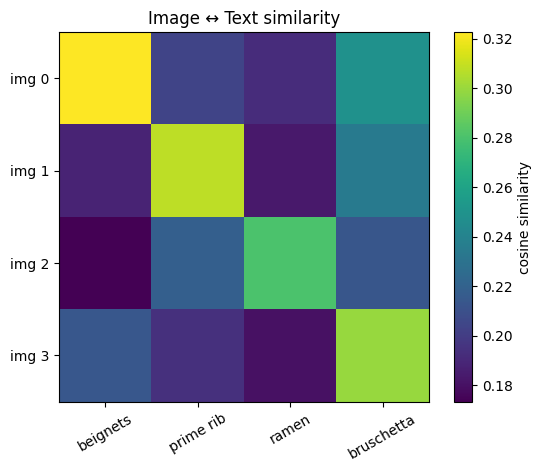

In [14]:
# مصورسازی ماتریس شباهت به‌صورت هیت‌مپ (Heatmap)
plt.imshow(similarity.detach().cpu().numpy(), cmap="viridis")
plt.colorbar(label="cosine similarity")
plt.xticks(range(4), demo_classes, rotation=30)
plt.yticks(range(4), ["img 0", "img 1", "img 2", "img 3"])
plt.title("Image ↔ Text similarity")
plt.show()
# توجه: بالاترین مقادیر عددی باید روی قطر اصلی ماتریس متمرکز باشند!


<div dir="rtl" style="text-align: right;">

---

# ۵. طبقه‌بندی صفر-شات (<span dir="ltr">Zero-Shot Classification</span>) با فرمول‌های دستی

یکی از شگفت‌انگیزترین توانمندی‌های مدل <span dir="ltr">CLIP</span>، قابلیت **طبقه‌بندی صفر-شات (<span dir="ltr">Zero-Shot Learning</span>)** است؛ یعنی توانایی طبقه‌بندی تصویر در دسته‌هایی که مدل هرگز پیش از این به عنوان وظیفه طبقه‌بندی مستقیم برای آن‌ها تعلیم ندیده است!

<div style="border-right: 4px solid #3182ce; padding-right: 14px; margin: 15px 0;">

**تفاوت بنیادین با طبقه‌بندی سنتی:**
* **روش سنتی:** نیاز به یک لایه خطی با ابعاد ثابت <span dir="ltr">(D, num_classes)</span> دارد که با برچسب‌های مشخص آموزش دیده باشد. افزودن یک کلاس جدید مستلزم بازآموزی شبکه است.
* **روش صفر-شات در <span dir="ltr">CLIP</span>:** هیچ لایه طبقه‌بندی‌کننده‌ای در کار نیست! ما برای هر کلاس یک پرامپت متنی (مثلاً <code dir="ltr">"a photo of pizza"</code>) می‌نویسیم و بردارهای تعبیه آن‌ها ماتریس وزن کلاسیفایر را تشکیل می‌دهند. هر کلاسی که بیشترین شباهت کسینوسی را با تصویر داشته باشد، پیش‌بینی نهایی مدل خواهد بود.

</div>

در کدهای زیر تابع <code dir="ltr">zero_shot_classify</code> را کاملاً بر پایه عملیات پایه‌ای پایتورچ پیاده کرده و سپس دقت صفر-شات مدل را روی ۲۰۰ تصویر از مجموعه اعتبارسنجی ارزیابی می‌نماییم.

</div>

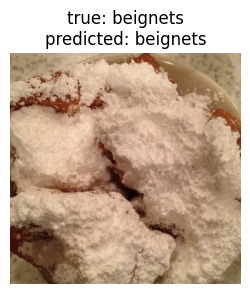

Top-5 Class probabilities:
  beignets                  0.999 ███████████████████████████████████████
  churros                   0.000 
  french toast              0.000 
  bread pudding             0.000 
  cannoli                   0.000 


In [ ]:
def zero_shot_classify(image, class_names, prompt_template="a photo of {}", text_features=None):
    """طبقه‌بندی یک تصویر صرفاً با محاسبات ریاضی دستی. خروجی: (pred_idx, probs)"""
    # -------------------------------------------------------------------------
    # TODO 4: پیاده‌سازی الگوریتم طبقه‌بندی صفر-شات با محاسبات دستی
    # راهنمایی:
    # ۱) Extract normalized embeddings
    # ۲) اگر text_features پاس داده نشده است:
    #    - برای هر دسته، پرامپت بسازید: [prompt_template.format(c) for c in class_names]
    #    - بردار تعبیه آن‌ها را با get_text_embedding گرفته و با normalize نرمال‌سازی کنید -> ابعاد (num_classes, 512)
    # calculate the scaled logits in and apply softmax
    # 3) برگرداندن جفت (pred_idx, probs):
    #    - pred_idx: ایندکس بیشترین احتمال -> probs.argmax(-1).item()
    #    - probs: احتمالات اولین نمونه -> probs[0]
    # -------------------------------------------------------------------------
    raise NotImplementedError("TODO 4 را تکمیل کنید: تابع zero_shot_classify")

# آزمایش روی یک تصویر نمونه (کدهای ارزیابی و رسم بدون نیاز به تغییر)
img_idx = 3
test_img = food101["validation"][img_idx]["image"].convert("RGB")
true_label = class_names[food101["validation"][img_idx]["label"]]
pred_idx, probs = zero_shot_classify(test_img, class_names)

plt.figure(figsize=(3, 3)); plt.imshow(test_img); plt.axis("off")
plt.title(f"true: {true_label}\npredicted: {class_names[pred_idx]}")
plt.show()

print("Top-5 Class probabilities:")
for c, p in sorted(zip(class_names, probs.tolist()), key=lambda x: -x[1])[:5]:
    bar = "█" * int(p * 40)
    print(f"  {c:<25} {p:.3f} {bar}")

In [16]:
from tqdm import tqdm
# ارزیابی دقت روی زیرمجموعه‌ای از داده‌های اعتبارسنجی (کاملاً صفر-شات و بدون آموزش!)
def zero_shot_accuracy(dataset, n=200, prompt_template="a photo of {}"):
    prompts = [prompt_template.format(c) for c in class_names]
    text_features = normalize(get_text_embedding(prompts))

    correct = 0
    for i in tqdm(range(n)):
        img = dataset[i]["image"].convert("RGB")
        pred, _ = zero_shot_classify(img, class_names, text_features=text_features)
        correct += (pred == dataset[i]["label"])
    return correct / n

acc_before = zero_shot_accuracy(food101["validation"], n=200)
print(f"Zero-shot accuracy (200 validation images): {acc_before:.1%}")


100%|██████████| 200/200 [00:03<00:00, 64.29it/s]

Zero-shot accuracy (200 validation images): 94.0%


<div dir="rtl" style="text-align: right;">

## ۵-الف. اهمیت مهندسی پرامپت (<span dir="ltr">Prompt Engineering</span>) در مدل‌های چندوجهی

مدل <span dir="ltr">CLIP</span> با متن‌ها و کپشن‌های واقعی صفحات اینترنت (مانند توضیحات طبیعی کنار تصاویر) آموزش دیده است، نه با برچسب‌های خشک و تک‌کلمه‌ای.

به همین خاطر، قالب متنی که برای معرفی کلاس‌ها استفاده می‌کنیم تأثیر مستقیمی بر دقت ارزیابی دارد. برای نمونه، قالب <code dir="ltr">"a photo of a pizza"</code> با توزیع جملات آموزش مدل سازگاری بسیار بیشتری دارد تا صرفاً کلمه <code dir="ltr">"pizza"</code>.
در سلول زیر، این دو الگو را با هم مقایسه می‌کنیم تا اثر مهندسی پرامپت را به وضوح مشاهده نمایید.

</div>

In [ ]:
templates = {
    "bare label":        "{}",
    "a photo of {}":     "a photo of {}",
    # -------------------------------------------------------------------------
    # TODO 5: پرامپت پیشنهادی خود را طراحی کرده و در این دیکشنری قرار دهید!
    # پرامپت‌هایی که زمینه بیشتری از محیط یا ظاهر غذا می‌دهند را امتحان کنید.
    # -------------------------------------------------------------------------
    # "my custom prompt": "...",
}
n = 200
for name, tpl in templates.items():
    # محاسبه مجدد دقت با قالب پرامپت متفاوت
    acc = zero_shot_accuracy(food101["validation"], n=n, prompt_template=tpl)
    print(f"{name:<25} accuracy = {acc:.1%}")

# آیا پرامپت طراحی‌شده شما می‌تواند دقت بهتری نسبت به قالب استاندارد کسب کند؟

100%|██████████| 200/200 [00:03<00:00, 63.60it/s]


bare label                accuracy = 94.5%


100%|██████████| 200/200 [00:02<00:00, 67.93it/s]

a photo of {}             accuracy = 94.0%


<div dir="rtl" style="text-align: right;">

---

# ۶. ⭐ شاهکار آموزش تقابلی: پیاده‌سازی تابع زیان متقارن (<span dir="ltr">InfoNCE Loss</span>) از صفر

اکنون به عمیق‌ترین و بنیادی‌ترین بخش کارگاه می‌رسیم: **مدل <span dir="ltr">CLIP</span> در مرحله آموزش چگونه یاد گرفته است این بردارهای شگفت‌انگیز را هم‌تراز کند؟**

فرض کنید یک بچ شامل $N$ جفت هم‌خوان (تصویر، متن) داریم:
<div dir="ltr" style="text-align: center; margin: 10px 0;">
$$\{(I_1, T_1), (I_2, T_2), \dots, (I_N, T_N)\}$$
</div>
ماتریس شباهت $N \times N$ به صورت $S_{ij} = s \cdot (\hat{I}_i \cdot \hat{T}_j)$ محاسبه می‌شود:

<div style="border-right: 4px solid #ed8936; padding-right: 14px; margin: 15px 0;">

🎯 **منطق یادگیری تقابلی (<span dir="ltr">Contrastive Objective</span>):**
* **عناصر روی قطر اصلی ماتریس ($i = j$):** جفت‌های مثبت (<span dir="ltr">Positive Pairs</span>) هستند؛ یعنی تصویر واقعی و متن مربوط به خودش. مدل باید شباهت آن‌ها را **بیشینه (HIGH)** کند.
* **عناصر خارج از قطر اصلی ($i \neq j$):** جفت‌های منفی (<span dir="ltr">Negative Pairs</span>) هستند؛ یعنی تصویر با متن سایر نمونه‌های درون بچ جفت شده است. مدل باید شباهت آن‌ها را **کمینه (LOW)** کند.

</div>

### فرمول ریاضی تابع زیان متقارن (<span dir="ltr">Symmetric InfoNCE Loss</span>):
آموزش به صورت یک مسئله دسته‌بندی دوطرفه با آنتروپی متقاطع (<span dir="ltr">Cross-Entropy</span>) فرمول‌بندی می‌شود که برچسب حقیقی هر نمونه دقیقاً اندیس خودش است (<code dir="ltr">targets = [0, 1, ..., N-1]</code>):

1. **زیان تصویر به متن (<span dir="ltr">Image-to-Text Loss</span>):** برای هر سطر تصویر $i$، به دنبال پیش‌بینی صحیح متن $i$ هستیم:
<div dir="ltr" style="text-align: center; margin: 8px 0;">
$$\mathcal{L}_{I \to T}^{(i)} = -\log \frac{\exp(S_{ii})}{\sum_{j=1}^N \exp(S_{ij})}$$
</div>

2. **زیان متن به تصویر (<span dir="ltr">Text-to-Image Loss</span>):** برای هر ستون متن $j$، به دنبال پیش‌بینی صحیح تصویر $j$ هستیم (محاسبه روی ستون‌های ماتریس یا سطرهای ماتریس ترانهاده $S^T$):
<div dir="ltr" style="text-align: center; margin: 8px 0;">
$$\mathcal{L}_{T \to I}^{(j)} = -\log \frac{\exp(S_{jj})}{\sum_{i=1}^N \exp(S_{ij})}$$
</div>

3. **زیان نهایی کل:** میانگین حسابی دو زیان فوق:
<div dir="ltr" style="text-align: center; margin: 8px 0;">
$$\mathcal{L}_{\text{CLIP}} = \frac{1}{2} \left( \frac{1}{N}\sum_{i=1}^N \mathcal{L}_{I \to T}^{(i)} + \frac{1}{N}\sum_{j=1}^N \mathcal{L}_{T \to I}^{(j)} \right)$$
</div>

در سلول زیر این تابع را با PyTorch پیاده کرده و عملکرد آن را با یک تست صحت‌سنجی (<span dir="ltr">Sanity Check</span>) بررسی می‌نماییم.

</div>

In [ ]:
def clip_contrastive_loss(image_embeddings, text_embeddings, logit_scale):
    """
    پیاده‌سازی دستی تابع زیان تقابلی متقارن InfoNCE

    image_embeddings: ویژگی‌های خام و نرمال‌نشده تصویر با بعد (N, D)
    text_embeddings:  ویژگی‌های خام متن با بعد (N, D)
    خروجی: مقدار اسکالر تابع زیان
    """
    # -------------------------------------------------------------------------
    # TODO 6: پیاده‌سازی دستی تابع زیان تقابلی متقارن InfoNCE
    # راهنمایی:
    # don't forget to calculate the loss when mapping text -> image and image -> text
    # -------------------------------------------------------------------------
    raise NotImplementedError("TODO 6 را تکمیل کنید: تابع clip_contrastive_loss")

# --- بررسی درستی عملکرد: جفت‌های تقریباً یکسان -> مقدار زیان نزدیک به صفر
N, D = 8, 512
perfect = normalize(torch.randn(1, D)).repeat(N, 1) + torch.randn(N, D) * 0.01
print("loss on (nearly) identical pairs :", clip_contrastive_loss(perfect, perfect, torch.tensor(100.0)).item())

loss on (nearly) identical pairs : 0.04731907695531845


<div dir="rtl" style="text-align: right;">

## 🧠 پرسش‌های سنجش درک مفهومی (<span dir="ltr">Check Your Understanding</span>)

پس از تکمیل و اجرای کدها، درباره سه سوال مفهومی زیر بیندیشید و پاسخ تحلیلی خود را یادداشت فرمایید:

<div style="border-right: 4px solid #3182ce; padding-right: 14px; margin: 16px 0;">

**۱. چرا برای یک ماتریس شباهت کاملاً تصادفی، مقدار اولیه تابع زیان تقابلی حدود $\ln(N)$ است؟**  
*راهنمایی: فرض کنید مدل هیچ دانشی ندارد و برای هر یک از $N$ گزینه شانس برابری قائل است ($p = 1/N$). فرمول آنتروپی متقاطع در این وضعیت چه مقداری تولید می‌کند؟*

</div>

<div style="border-right: 4px solid #3182ce; padding-right: 14px; margin: 16px 0;">

**۲. چرا بزرگ بودن اندازه بچ (<span dir="ltr">Batch Size - N</span>) برای یادگیری تقابلی در <span dir="ltr">CLIP</span> حیاتی است؟**  
*راهنمایی: برای هر تصویر، چه تعداد نمونه منفی در بچ وجود دارد؟ افزایش نمونه‌های منفی چه تأثیری بر کیفیت تفکیک‌پذیری و استخراج ویژگی‌های ظریف (<span dir="ltr">Hard Negatives</span>) دارد؟*

</div>

<div style="border-right: 4px solid #3182ce; padding-right: 14px; margin: 16px 0;">

**۳. نقش پارامتر مقیاس لاجیت (<span dir="ltr">Logit Scale</span>) یا ضریب دما در جریان گرادیان چیست؟**  
*راهنمایی: اگر مقادیر کسینوسی بین ۰٫۱ تا ۰٫۳ بدون هیچ اسکیلی به Softmax بروند چه رخ می‌دهد؟ اگر ضریب خیلی بزرگ یا خیلی کوچک باشد، وضعیت گرادیان‌ها و پدیده اشباع چگونه خواهد بود؟*

</div>

<div style="border-right: 4px solid #38a169; padding-right: 14px; margin: 16px 0;">

### 🎯 ملاک موفقیت شما در این تمرین:
* اجرای بدون خطای تابع <code dir="ltr">show_cls_attention</code> و مشاهده هیت‌مپ توجه لایه‌ها.
* محاسبه صحیح شباهت کسینوسی و لاجیت‌ها در ماتریس شباهت.
* اجرای موفق <code dir="ltr">zero_shot_classify</code> و مشاهده خروجی درصدهای پیش‌بینی.
* به دست آوردن مقدار زیان نزدیک به صفر روی جفت‌های یکسان در تست صحت‌سنجی <code dir="ltr">clip_contrastive_loss</code>.

</div>

</div>